# Model simplification

## The model's inputs

The reference model is Model 17's `S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st` arm (`Model/dip4_ladder_checkpoints`, 5 fold checkpoints, evaluated under the rej wall band). Every bout it emits is drawn from three chained heads, turn → step → interval, conditioned on **47 input columns** built by `scripts/fit_MLP_border.build_feature_matrix` in the order below, plus the per-fish latent and the slow state listed at the end. Every stimulus column is exactly 0 on bouts without dots, so "no stimulus" is a well-defined input state.

| # | category | columns | what each column is | zero when |
|---|---|---|---|---|
| 1–8 | **turn history** | 8 | the fish's previous 8 turn angles, lag 1 … 8, in degrees over a fixed scale; a lag that would reach across a > 10 s pause is zeroed | early in a run (fewer than *k* bouts since the pause) |
| 9–26 | **moving-dot stimulus** (the *shoal* block, 18) | `act` | 1 while dots are on screen | no dots |
| | | `moving` | 1 on moving-dot bouts | static dots, no dots |
| | | `nz` | group size, log₂ N / log₂ 8 (N ∈ {1, 2, 4, 6, 8}) | no dots |
| | | `rz` | log fish-to-centroid range, centred on 70 px, ±1 = ±2 octaves, clipped | no dots |
| | | `gs1–gs4` | sin(bearing) × a 4-knot Gaussian **range basis** (knots at 25, 50, 90, 160 px; the 4 weights sum to 1) | no dots |
| | | `gc1–gc4` | cos(bearing) × the same range basis | no dots |
| | | `gns1–gns4` | group size × sin(bearing) × the range basis | no dots |
| | | `mv_sin`, `mv_cos` | sin / cos(bearing) on moving-dot bouts only — the only columns that separate the moving from the static law inside this block | static dots, no dots |
| 27–29 | **wall** (raw border block) | 3 | normalised distance to the dish wall; sin and cos of the bearing to the dish centre, both relative to the previous travel heading | — (always on) |
| 30–35 | **kinematic history** | 6 | the previous 3 step lengths (log, z-scored) and the previous 3 intervals as **deviations from the fish's own running level** (an EMA of its past log intervals, 250-bout time constant), so a long interval predicts the next one without feeding back into the level | across a pause |
| 36 | **lag validity** | 1 | min(bouts since the run began, 8) / 8 — tells the net a zero lag is padding, not a straight bout | — |
| 37 | **block clock** | 1 | exp(−t / 4 s) with t the time since the current stimulus block began — "a stimulus just started" | pauses, and late in a block |
| 38 | **run clock** | 1 | exp(−bouts since the last pause / 30) — the post-pause transient (slower, shorter, more central for ~60 bouts) | deep inside a run |
| 39 | **aligned-and-far** | 1 | range × cos(bearing) / 100 px for moving dots — the pursuit interaction the shoal basis cannot express with the dots straight ahead | static dots, no dots |
| 40–47 | **static-dot bearing** | 8 | sin(bearing) × the range basis and cos(bearing) × the range basis, on **static-dot** bouts only — gives the turn head a static law of its own (the sign flip near static dots) | moving dots, no dots |

Bearings are egocentric, in the travel frame (`phi_ref = psi_ref = 'travel'`), positive to the fish's left. The stimulus geometry (bearing, range) is taken from the active dots' centroid.

**Not inputs, but part of every rollout**

| component | what it does |
|---|---|
| per-fish latent **z** (2-d, level-only) | a random individual per rollout, drawn from the fitted prior, shifting the turn logit and the step and interval locations; one global loading gain 0.7 / 1.2 per fold |
| **slow state** (AR(1), 70-bout time constant) | within-trajectory drift loading on all three heads — the across-window persistence of tempo and step |
| **heads** | turn: a 5-component mixture over the turn angle — one Gaussian forward component and two Gamma components per side (left / right), weights and shapes set by the net; step: 2-component log-normal; interval: 3-component log-normal truncated at 10 s (chained order turn → step → interval) |
| **turn-head weight** in training | pursuit bouts (moving dots ≥ 60 px) weighted ×3 on the turn head only (`w3ft`) |
| **generation-time rules** | rej: a bout landing 2–10 mm from the wall is redrawn (max 20 draws); dots re-anchored to the simulated fish at every block onset; the dish guardrail |

**What an ablation can switch off, by column group:** the whole stimulus (9–26, 39, 40–47 → the no-dot fish), the moving law only (`moving`, `mv_sin`, `mv_cos`, 39), the static law only (40–47), group size (`nz`, `gns1–4`), range (`rz` and the basis products), the onset transient (37), the wall (27–29), the kinematic memory (30–35), the turn memory (1–8), the run transient (38), z, or the slow state.


## Which inputs the fitted model actually uses — teacher-forced permutation test

Each fold checkpoint scored its **held-out** fish (Metric A, the per-bout log-density with z marginalised) with one column group **shuffled across the bouts where the group is active** (dots on / moving / static / all bouts), zeros left in place; for the three groups suspected of being inert the group was also **zeroed** outright, which is the fairer test for an interaction column (0 is an in-distribution value, a shuffled pairing is not). The drop in bits/bout is what the model loses without the information; `worse in` = fish out of 15 whose likelihood got worse. Baseline: 13.344 bits/bout joint (turn 7.627, step 4.513, interval 1.203). Script: `perm_importance.py` (scratchpad), 17 min.

| column group | shuffled: drop, bits/bout | se | turn · step · interval | worse in | zeroed: drop | worse in |
|---|---|---|---|---|---|---|
| kinematic history (30–35) | **0.554** | 0.040 | 0.088 · 0.312 · 0.154 | 15 | | |
| wall (27–29) | **0.283** | 0.020 | 0.171 · 0.065 · 0.047 | 15 | | |
| turn history (1–8) | 0.080 | 0.009 | 0.072 · 0.003 · 0.005 | 15 | | |
| `mv_sin`, `mv_cos` (25–26) | **0.043** | 0.007 | 0.034 · 0.002 · 0.007 | 15 | 0.022 | 11 |
| run clock (38) | 0.041 | 0.006 | 0.020 · 0.009 · 0.013 | 14 | | |
| range basis × bearing `gs`, `gc` (13–20) | **0.039** | 0.006 | 0.029 · 0.008 · 0.003 | 14 | | |
| static block (40–47) | 0.017 | 0.002 | 0.012 · 0.004 · 0.002 | 15 | | |
| `rz` log range (12) | 0.009 | 0.002 | 0.003 · 0.004 · 0.002 | 14 | | |
| `gns` group size × bearing × basis (21–24) | 0.009 | 0.002 | 0.006 · 0.003 · 0.000 | 14 | **0.002** | 10 |
| `act` + `moving` (9–10) | 0.005 | 0.001 | 0.001 · 0.001 · 0.003 | 13 | | |
| `align` (39) | 0.004 | 0.001 | 0.002 · 0.001 · 0.002 | 13 | **0.001** | 10 |
| block clock (37) | 0.004 | 0.001 | 0.002 · 0.001 · 0.000 | 13 | | |
| `nz` group size (11) | 0.002 | 0.000 | 0.001 · 0.001 · 0.000 | 14 | | |

**Reading.** The likelihood lives in the kinematic memory and the wall (0.84 of the 1.1 bits any group can take away); the whole stimulus is worth about 0.13 bits/bout teacher-forced, which is the familiar point that stimulus responses are small per-bout biases that only integrate into visible behaviour over a block. Within the stimulus:

- **Needed**: `mv_sin`/`mv_cos` — the moving-dot bearing main effect is the single strongest stimulus group, not a redundancy with the static block (the two condition-specific sets sit on top of a shared basis, and the moving one is the one the turn head leans on); the range basis × bearing; the static block; `rz`.
- **Not read, teacher-forced**: `align` (zeroed: 0.001 bits/bout, 10/15 fish) and `gns` (zeroed: 0.002, 10/15) — the shuffle drop they show is the cost of an impossible pairing, not of lost information. The free-run check in the next section confirms it for `align` and **overturns it for `gns`**: zeroing `gns` halves the approach dip and the dot-count grading over a block, a group-size effect a per-bout likelihood cannot see. Both tests zero a column in the *fitted* model; neither says what training without the column would give.
- **Small but real**: the block clock (13/15 fish), `act`/`moving`, and `nz` — group size is worth 0.002 bits/bout per bout, yet it is the only carrier of the plateau grading by N (4.6 mm in the profile against a real 6.0), the clearest case of a behaviour that is invisible per bout and obvious over a block.

Consequence for this study: Model 17 stays the reference as trained; ablations are done on this model by switching input groups off at rollout time (`scripts/input_ablation.zero_inputs`), and they are judged on rollouts, never on Metric A — see the next section for why.


## Does the 42-input model behave like the 47-input one? The dot profile with `align` and `gns` zeroed

The permutation test above is teacher-forced: it says the fitted model puts no weight on `align` and the four `gns` columns. The profile is the free-run reading, and it is the one the ablations are judged on, so the same question is asked here on rollouts: the five fold checkpoints roll out the recorded programme as they are, and again with those columns **zeroed inside the generator's own feature row** (`scripts/input_ablation.zero_inputs`, which rebinds the three functions the closed-loop generator builds its stimulus columns with; zero is an in-distribution value for every stimulus column). Same weights, no retraining.

Two things to keep in mind when reading the figure:

- **Rollout noise.** The notebook's profile blocks use 15 simulated fish, and at that count the dip and the dot-count grading move by a millimetre or more between two independent rollout sets of the *same* model. Here every variant uses 50 simulated fish (10 per fold model), and the unablated model is rolled out twice on independent streams (`standard` and `standard, seed 1`): the difference between those two rows is the noise floor any ablation has to clear.
- **Chaos, not effect.** Once any input differs, the same random streams produce different trajectories, so a variant's curve is not a perturbation of the standard curve but an independent draw from a (possibly identical) law. Only the *statistics* across the 50 fish are comparable, never the individual curves.

The figure shows one panel per stimulus condition, the real mean ± SEM across the 15 fish in black, one line per variant; the table underneath gives the headline numbers (moving error, dip, plateau, grading, static error and drift-away) per variant next to the real values.

### What the figure says (50 simulated fish per variant)

| variant | moving error (mm / real SEM) | dip (real 4.2) | plateau (real 17.3) | grading (real 6.0) | static error (mm / SEM) | static drift-away (real 0.58) |
|---|---|---|---|---|---|---|
| `standard` (47 inputs) | 1.67 / 1.28 | 2.60 | 18.1 | 5.1 | 1.48 / 0.94 | 0.52 |
| `standard, seed 1` (noise floor) | 1.76 / 1.38 | 2.27 | 18.3 | 5.0 | 1.69 / 1.08 | 0.47 |
| `no align` (46 inputs) | 1.43 / 1.09 | 2.60 | 17.4 | 5.3 | 1.33 / 0.85 | 0.50 |
| `no align, no gns` (42 inputs) | **2.36 / 1.89** | **1.52** | **19.4** | **2.8** | 1.55 / 1.08 | 0.55 |

- **The noise floor** between two independent rollout sets of the same model is about 0.3 mm on the dip, 0.2 mm on the plateau and 0.1 mm on the grading at this replicate count (and roughly three times that at the notebook blocks' 15 fish, which is why the 15-fish versions of this comparison swung in both directions).
- **`align` is not read by the fitted model in the free run either.** Every reading of `no align` sits inside the noise floor of the standard model (the moving error is if anything lower), consistent with the teacher-forced test. So it can be zeroed in the deployed model without changing its behaviour. That is the whole claim: whether the model could have been *trained* without it and come out the same is a different question, testable only by retraining against several seeds of the control, which no ladder here has (Model 24's three retrains without `align` landed inside the fit-to-fit draw, consistent with either reading).
- **`gns` is not.** Zeroing it halves the dip (2.6 → 1.5 mm), raises the plateau by 1.2 mm and cuts the dot-count grading from 5.1 to 2.8 mm — the 6- and 8-dot approach curves in the figure lose their descent while the 1- and 2-dot ones do not move. The static side is untouched, as it must be (the columns are zero on static bouts). Teacher-forced, zeroing `gns` costs 0.002 bits/bout; over a block it is half the grading. This is the same lesson as `nz`: a group-size effect is a small per-bout bias that only shows over a block, so a likelihood-based importance cannot see it, and **the free-run profile is the only test that counts for the ablations**.

**Conclusion.** The simplification is one column, not five: Model 17 does not read `align`, so the deployed model can run on 46 inputs and behave identically; the `gns` block stays. The reference model for the ablations is Model 17 as trained. An ablation is a same-weights zeroing by construction ("what does this fitted fish do without this input"), so the same-weights test above is the one that describes it, and its wording carries over: a zeroed group is *not read* by the fitted model, never *useless* for training.


In [ ]:
# Model 17's checkpoints and the rej band every evaluation uses; the rollout-time ablation switch.
import sys; sys.path.insert(0, "../scripts"); sys.path.insert(0, "../Model")
import os; os.chdir("../Model")                 # model_figures resolves checkpoint folders and assets from Model/
from input_ablation import zero_inputs, profile_variants, GNS
REJ = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
ARM = "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"

the plot in numbers: mv_err = mean |gen - real| over 0-60 s on the 2-8 moving-dot conditions (mm and real-SEM units); dip = approach amplitude within 20 s (mm) and its latency (s); plateau = 20-60 s level; grading = plateau(1 dot) - plateau(8 dots); static: err and drift-away over 0-20 s (mm/s)
                  n_sim_fish  runaway  mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                                    
REAL                      15        0       0.00        0.00  4.23  13.5    17.26       22.26     6.00       0.00        0.00          0.58
standard                  50        0       1.67        1.28  2.60   8.5    18.13       22.00     5.09       1.48        0.94          0.52
standard, seed 1          50        0       1.76        1.38  2.27   9.5    18.30       22.67     4.99       1.69        1.08          0.47
no a

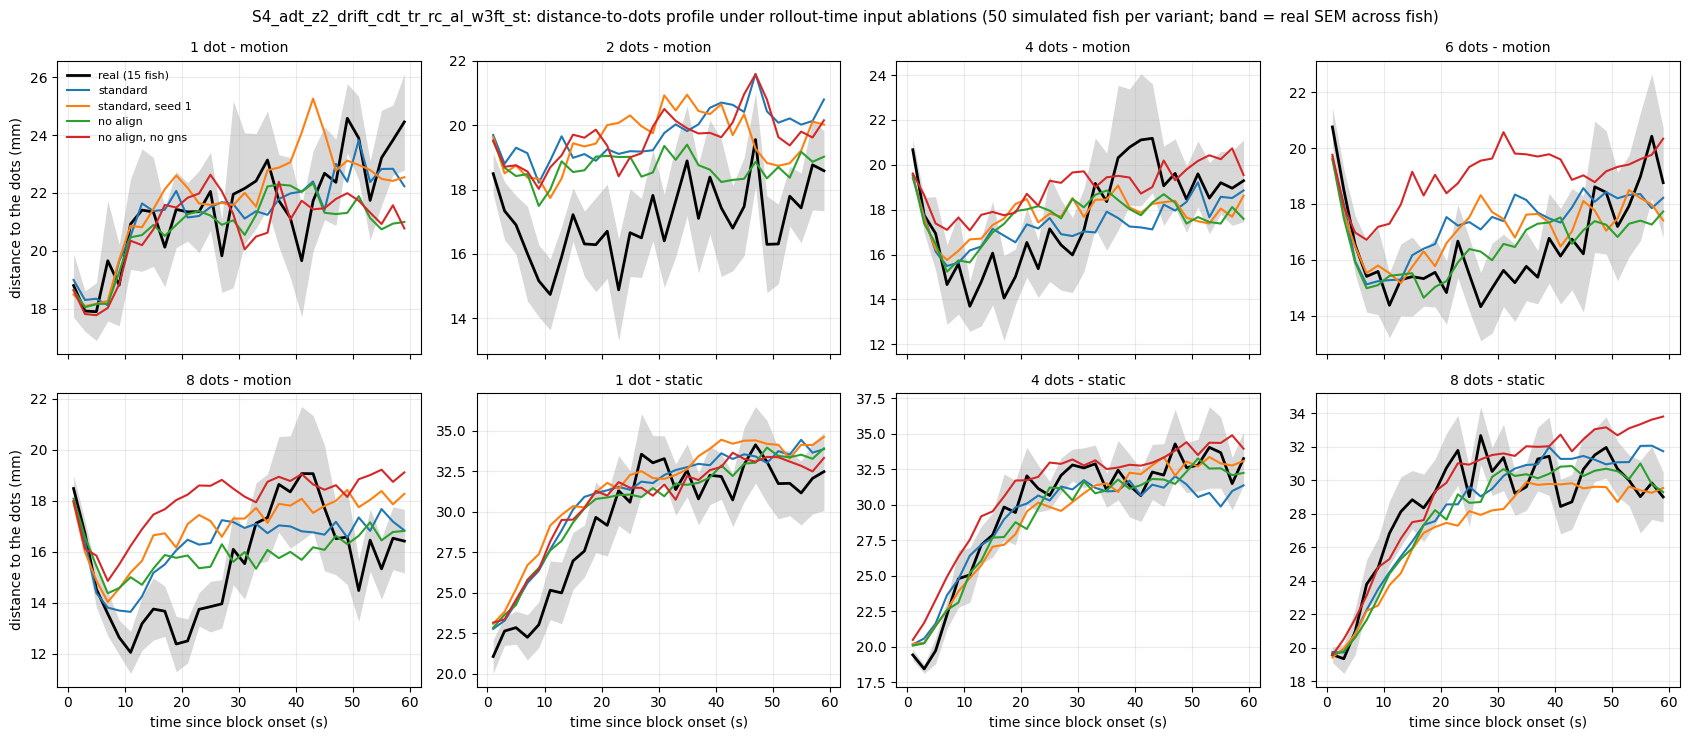

In [ ]:
# The dot-distance profile with the two inert input groups zeroed at rollout time, same weights: `standard` =
# Model 17 as evaluated everywhere; `standard, seed 1` = the same model on an independent set of rollout streams,
# i.e. the profile's own rollout-noise floor at this replicate count; `no align`; `no align, no gns` = the 42-input
# model. 10 rollouts per fold model = 50 simulated fish per variant (the notebook blocks use 15).
simp_tab, simp_gens = profile_variants("dip4_ladder_checkpoints", ARM,
    {"standard": {}, "standard, seed 1": {"seed": 1}, "no align": {"align": True},
     "no align, no gns": {"align": True, "shoal_cols": GNS}}, rej=REJ, r_per_model=10)